# **AI Harness and Loop Engineering**

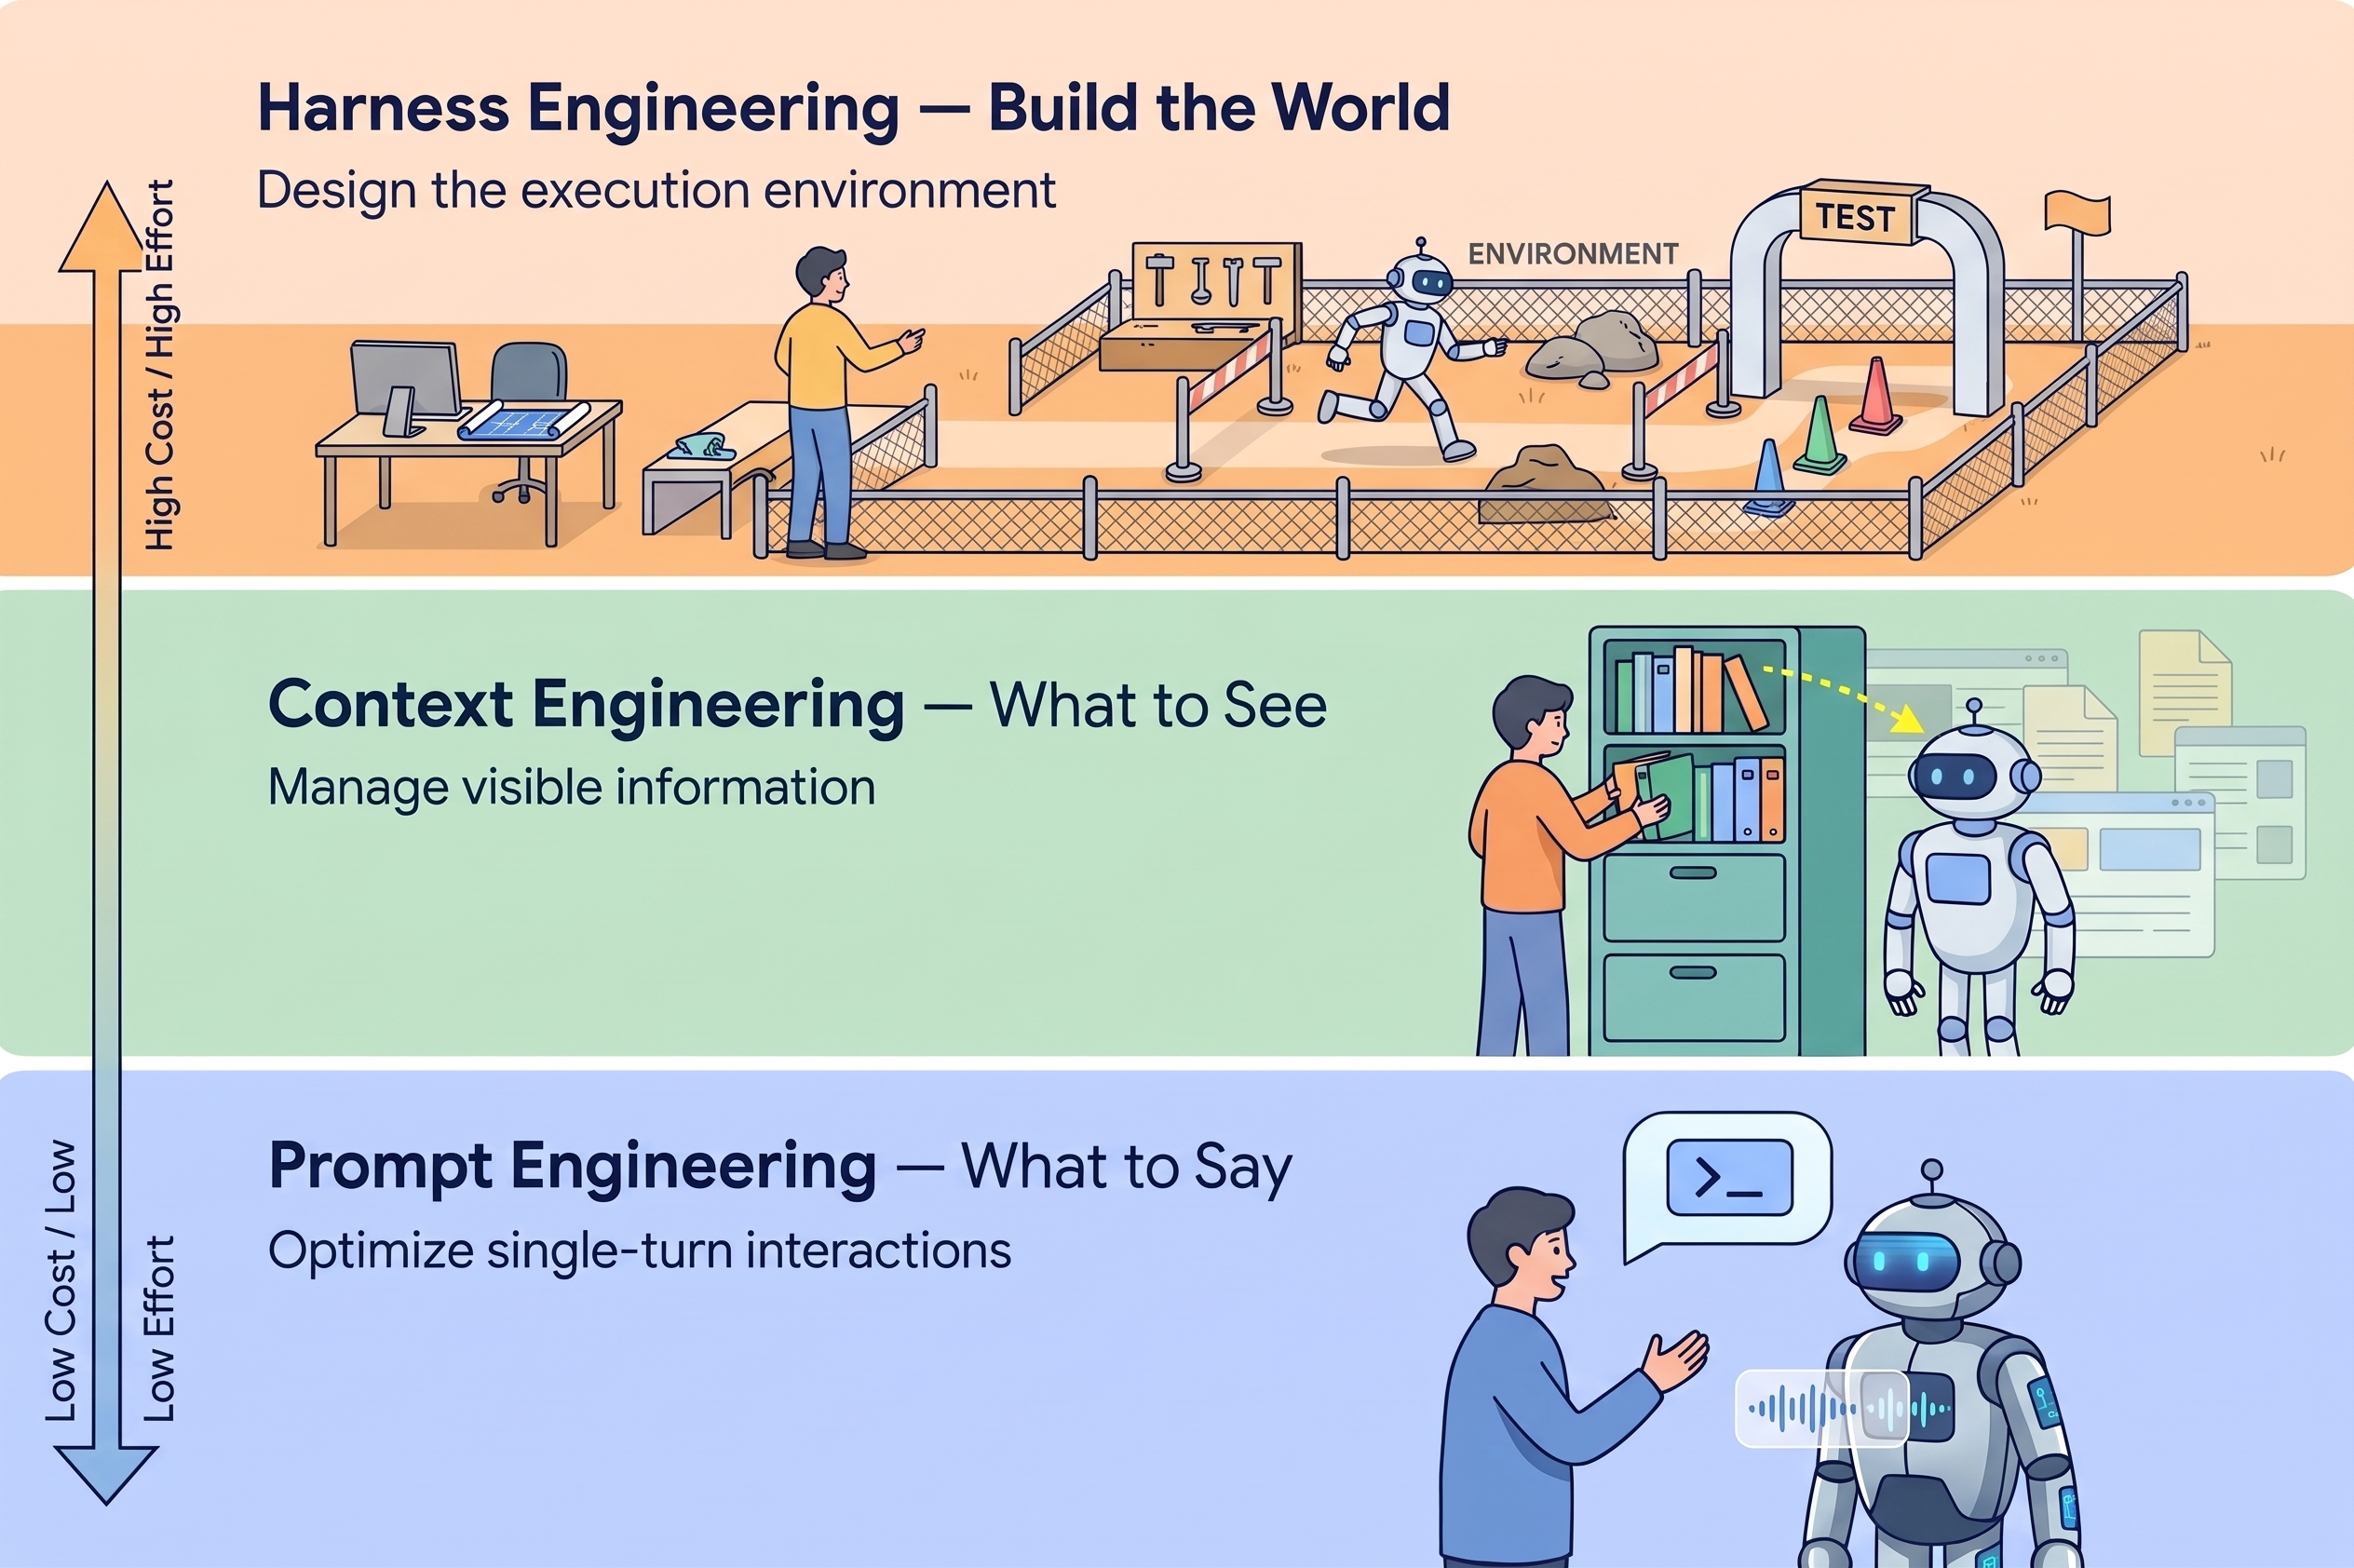

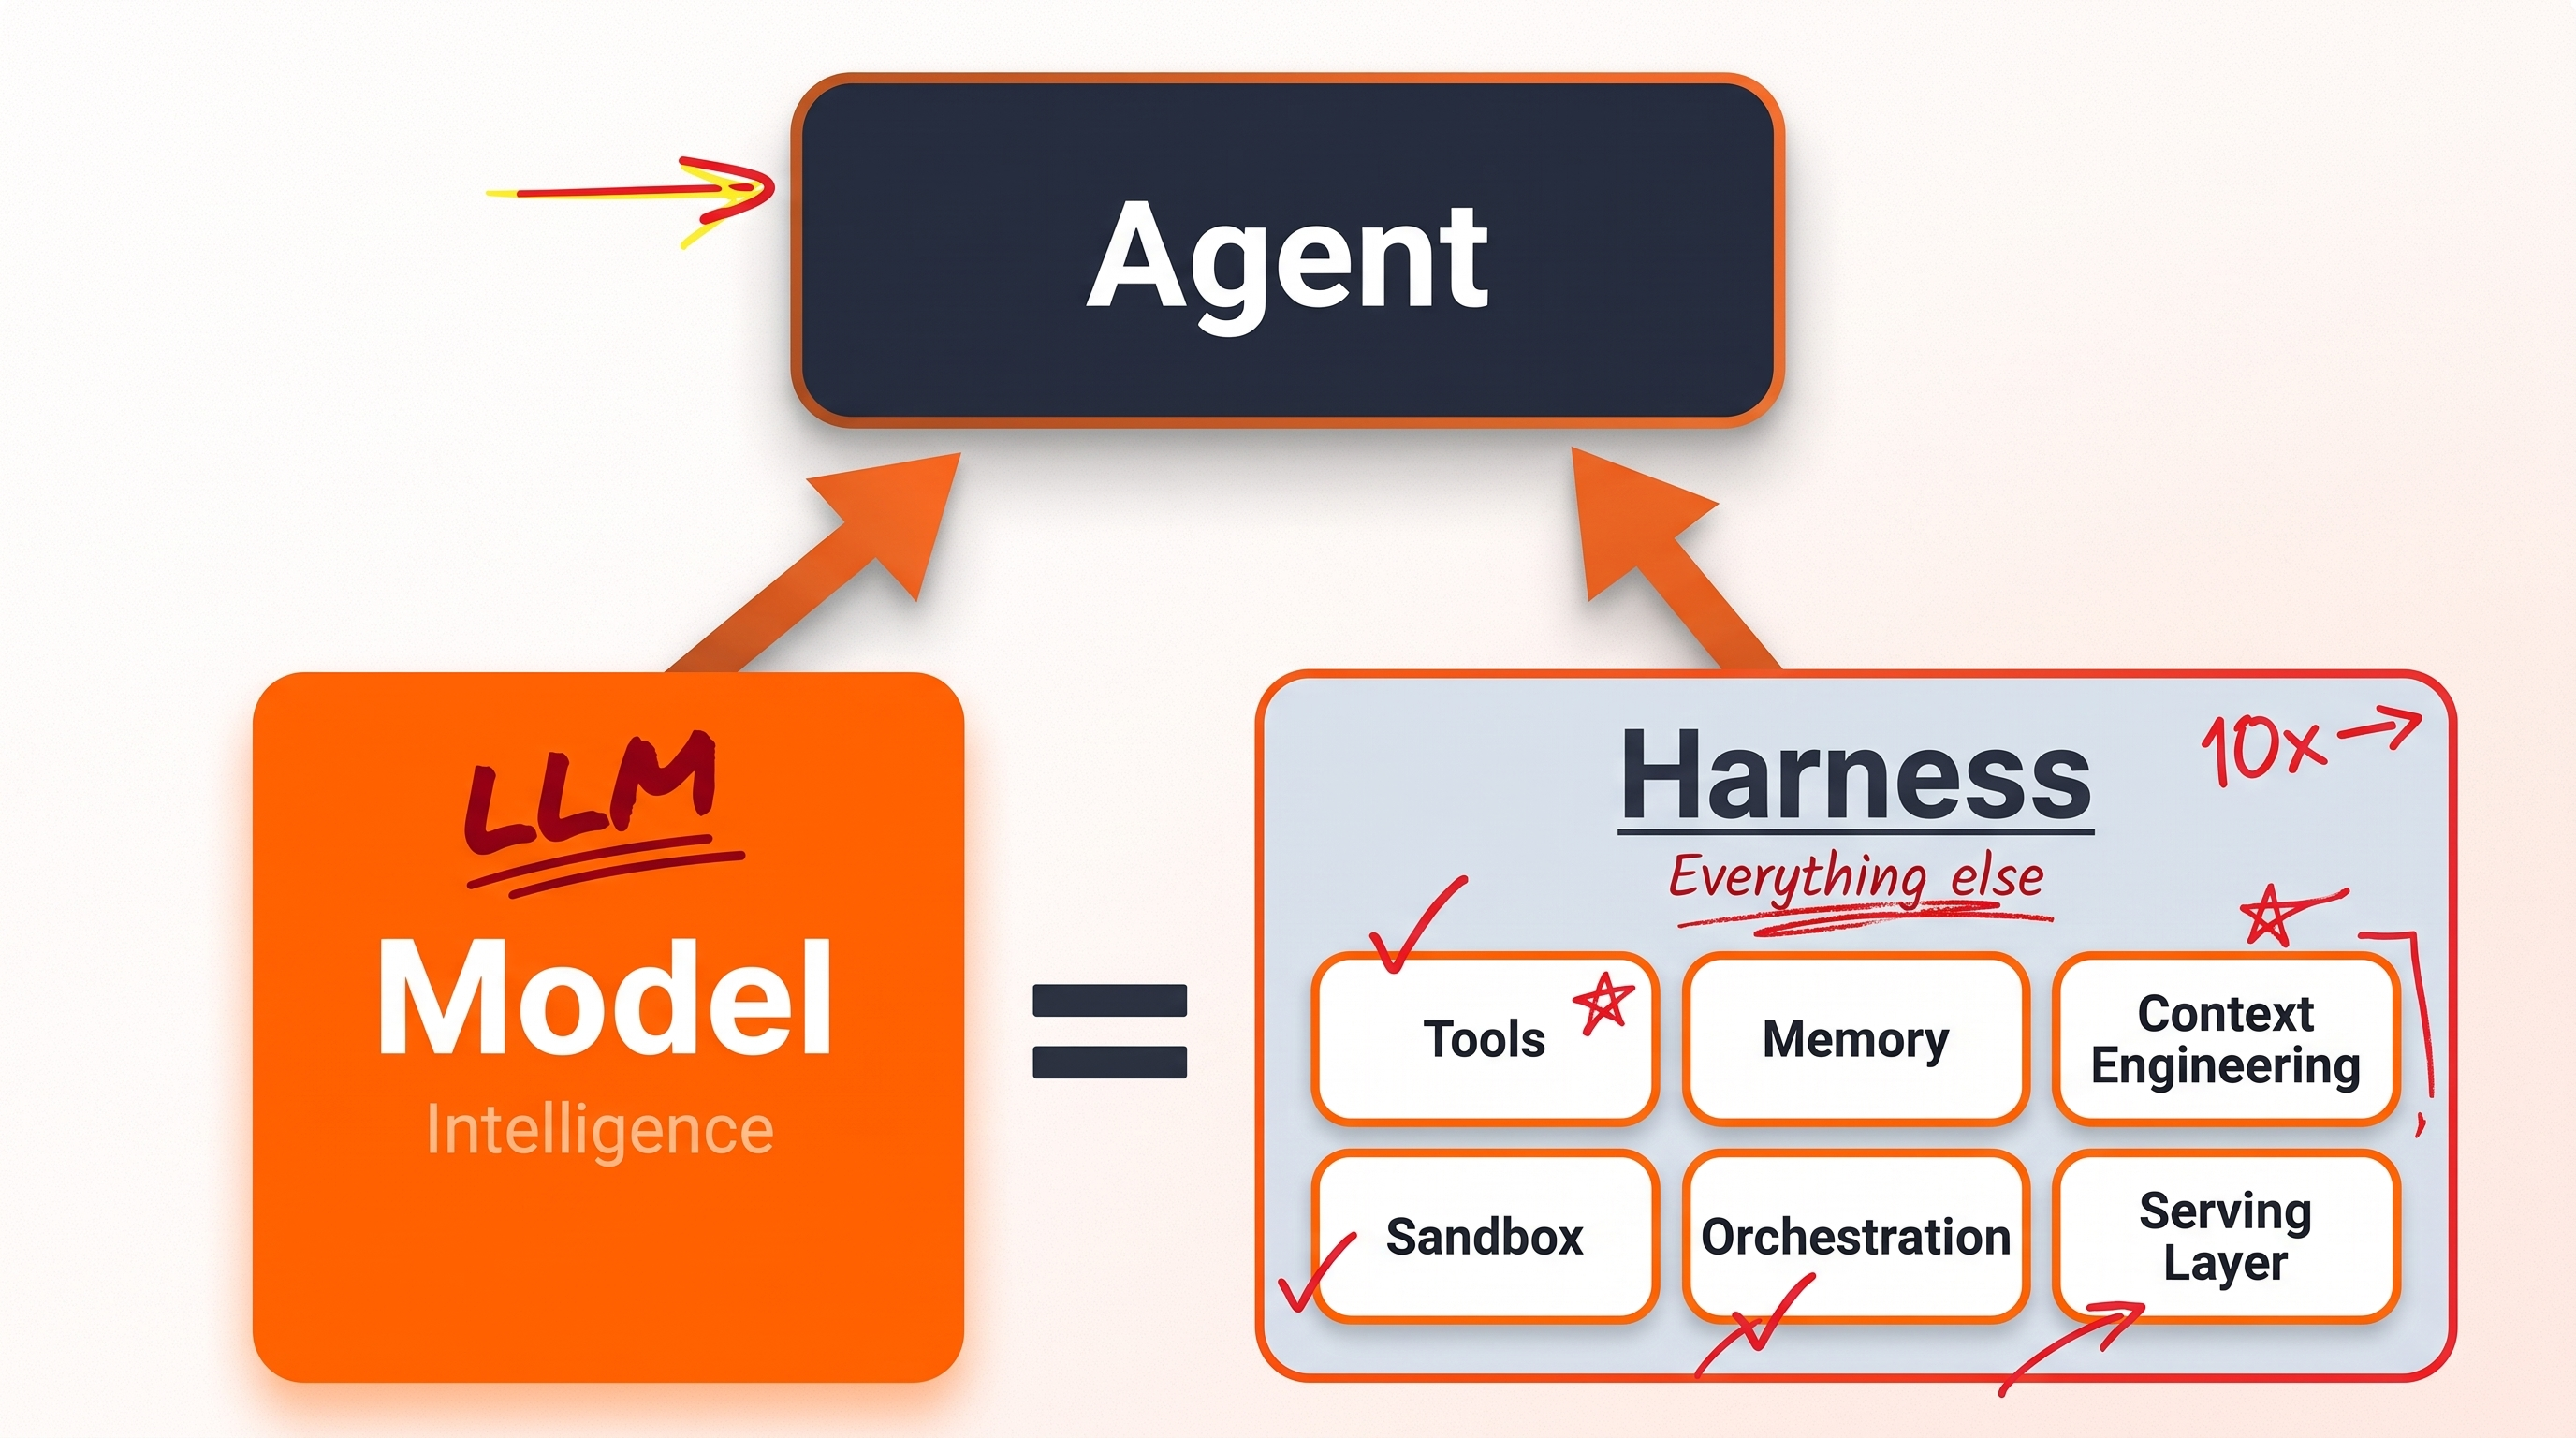

The LLM supplies reasoning and language capabilities. The harness controls what information the LLM receives, what tools it can use, how its outputs are validated, how failures are handled, and when the task is considered finished.

```text
                    ┌───────────────┐
User request ──────►│   CONTEXT     │
                    │ instructions  │
                    │ memory        │
                    │ retrieved docs│
                    └───────┬───────┘
                            │
                            ▼
                     ┌─────────────┐
                     │     LLM     │
                     │ reasoning   │
                     └──────┬──────┘
                            │
                   decides what to do
                            │
             ┌──────────────┼──────────────┐
             ▼              ▼              ▼
        ┌─────────┐    ┌──────────┐   ┌─────────┐
        │ Search  │    │ Database │   │ Python  │
        └────┬────┘    └────┬─────┘   └────┬────┘
             │              │              │
             └──────────────┼──────────────┘
                            ▼
                    ┌───────────────┐
                    │ VALIDATION    │
                    │ schema        │
                    │ permissions   │
                    │ error checks  │
                    └───────┬───────┘
                            │
                     good? / bad?
                       │       │
                       │       └────► retry / repair
                       ▼
                     Answer
```

A production harness commonly handles things such as system instructions, context assembly, RAG, tool definitions, memory, state, permissions, structured output, retries, error recovery, logging, evaluation, human approval, token budgets, and stopping conditions.

```text
┌───────────────────────────────────────┐
│ 1. Context                            │
│ prompts, instructions, memory, RAG    │
├───────────────────────────────────────┤
│ 2. Model                              │
│ GPT / Claude / Qwen / Gemini          │
├───────────────────────────────────────┤
│ 3. Tools                              │
│ APIs, MCP, SQL, Python, search        │
├───────────────────────────────────────┤
│ 4. Control                            │
│ routing, loops, state, stopping       │
├───────────────────────────────────────┤
│ 5. Reliability                        │
│ validation, retries, guardrails       │
├───────────────────────────────────────┤
│ 6. Observability                      │
│ logs, traces, evaluations, metrics    │
└───────────────────────────────────────┘
```

Where loop engineering enters


![AI Agent Loop Engineering Infographic.png](<attachment:AI Agent Loop Engineering Infographic.png>)

```text
                 ┌──────────────┐           
                 │     LLM      │   
                 └──────┬───────┘
                        │
                        ▼
                  Decide action
                        │
                        ▼
                    Use tool
                        │
                        ▼
                  Observe result
                        │
                        ▼
                    Evaluate
                        │
               ┌────────┴────────┐
               │                 │
          Not finished         Finished
               │                 │
               └──────► LLM      ▼
                              Answer


                AGENT ENGINEERING
                       │
          ┌────────────┴────────────┐
          │                         │
          ▼                         ▼
   Harness Engineering        Loop Engineering

Everything surrounding       How the agent repeatedly
and supporting the model     reasons, acts, observes
                             and decides when to stop                              
```                              
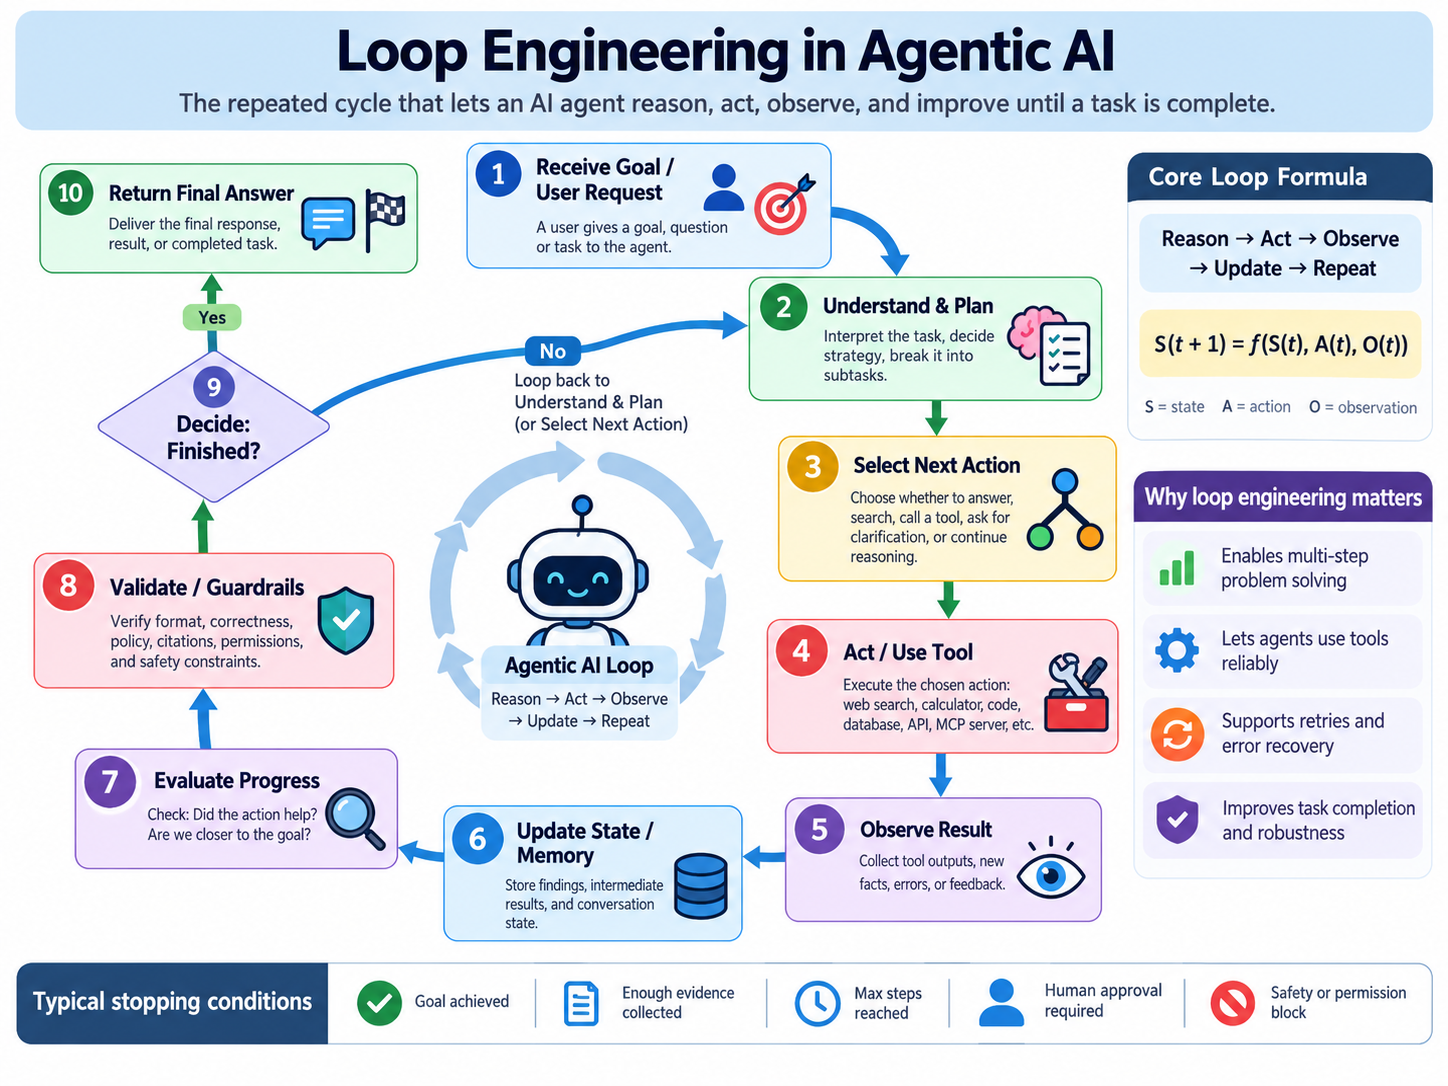

### Configure GPT credentials

Both examples load credentials and the endpoint from `.env`. Set `OPENAI_API_KEY`, `BASE_URL`, and optionally `OPENAI_MODEL` (defaults to `gpt-4o-mini`). Install `openai` and `python-dotenv` if needed.


## Example 1: Non-loop agent
This agent generates a customer-support reply only once.

In [1]:
import os
from dotenv import load_dotenv
from openai import OpenAI

# Load .env from this notebook's folder or a parent folder.
load_dotenv()

MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

if not api_key:
    raise ValueError("OPENAI_API_KEY is missing. Add it to your .env file.")
if not base_url:
    raise ValueError("BASE_URL is missing. Add it to your .env file.")

client = OpenAI(api_key=api_key, base_url=base_url)

def call_llm(prompt: str) -> str:
    """Send one request to the language model."""

    response = client.chat.completions.create(
        model=MODEL_NAME,
        messages=[
            {
                "role": "system",
                "content": "You are a helpful customer-support agent.",
            },
            {
                "role": "user",
                "content": prompt,
            },
        ],
        temperature=0.2,
    )

    return response.choices[0].message.content.strip()


task = """
        Write a customer-support reply for the following situation:

        A customer received a damaged laptop.
        Order ID: ORD-2026-101

        Requirements:
        - Apologize to the customer
        - Mention the order ID
        - Offer a replacement
        - Keep the response under 60 words
        """

answer = call_llm(task)

print("Final answer:")
print(answer)

Final answer:
Dear Customer,

I sincerely apologize for the inconvenience caused by receiving a damaged laptop with Order ID: ORD-2026-101. We understand how important this is to you, and we would be happy to arrange a replacement. Please let us know how you would like to proceed.

Thank you for your understanding.

Best regards,  
[Your Name]  
Customer Support


## Example 2: Loop agent

This version checks the answer and asks the LLM to fix any problems.

In [2]:
import os
from dotenv import load_dotenv
from openai import OpenAI

# Load .env from this notebook's folder or a parent folder.
load_dotenv()

MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

if not api_key:
    raise ValueError("OPENAI_API_KEY is missing. Add it to your .env file.")
if not base_url:
    raise ValueError("BASE_URL is missing. Add it to your .env file.")

client = OpenAI(api_key=api_key, base_url=base_url)

MAX_ITERATIONS = 3
ORDER_ID = "ORD-2026-101"

def call_llm(prompt: str) -> str:
    """Generate a customer-support response."""

    response = client.chat.completions.create(
        model=MODEL_NAME,
        messages=[
            {
                "role": "system",
                "content": (
                    "You are a helpful customer-support agent. "
                    "Follow every requirement carefully."
                ),
            },
            {
                "role": "user",
                "content": prompt,
            },
        ],
        temperature=0.2,
    )

    return response.choices[0].message.content.strip()


def evaluate_answer(answer: str) -> list[str]:
    """
    Check whether the answer satisfies all requirements.

    An empty list means that the answer passed.
    """

    problems = []
    lower_answer = answer.lower()

    # Check for an apology
    apology_words = ["sorry", "apologize", "apologies"]

    if not any(word in lower_answer for word in apology_words):
        problems.append("Add an apology to the customer.")

    # Check the order ID
    if ORDER_ID not in answer:
        problems.append(f"Mention the order ID {ORDER_ID}.")

    # Check whether a replacement was offered
    if "replacement" not in lower_answer:
        problems.append("Clearly offer a replacement.")

    # Check the word limit
    word_count = len(answer.split())

    if word_count > 60:
        problems.append(
            f"Reduce the response to under 60 words. "
            f"Current length: {word_count} words."
        )

    return problems


task = f"""
        Write a customer-support reply for the following situation:

        A customer received a damaged laptop.
        Order ID: {ORDER_ID}

        Requirements:
        - Apologize to the customer
        - Mention the order ID
        - Offer a replacement
        - Keep the response under 60 words
        """

feedback = "No previous feedback."
previous_answer = ""

for iteration in range(1, MAX_ITERATIONS + 1):

    print(f"\n--- Iteration {iteration} ---")

    prompt = f"""
            Original task:
            {task}

            Previous answer:
            {previous_answer or "No previous answer."}

            Feedback:
            {feedback}

            Write an improved final response.
            """

    # Agent performs an action
    answer = call_llm(prompt)

    print("\nGenerated answer:")
    print(answer)

    # System evaluates the action
    problems = evaluate_answer(answer)

    if not problems:
        print("\nEvaluation: PASSED")
        print("\nFinal answer:")
        print(answer)
        break

    print("\nEvaluation: FAILED")

    for problem in problems:
        print(f"- {problem}")

    # Feedback becomes input for the next iteration
    feedback = "\n".join(f"- {problem}" for problem in problems)
    previous_answer = answer

else:
    print("\nMaximum iterations reached.")
    print("Returning the best available answer:")
    print(previous_answer)


--- Iteration 1 ---

Generated answer:
Dear Customer,

I sincerely apologize for the inconvenience caused by receiving a damaged laptop with Order ID: ORD-2026-101. We understand how important this is to you and would like to offer a replacement. Please let us know how you would like to proceed.

Best regards,  
[Your Name]  
Customer Support

Evaluation: PASSED

Final answer:
Dear Customer,

I sincerely apologize for the inconvenience caused by receiving a damaged laptop with Order ID: ORD-2026-101. We understand how important this is to you and would like to offer a replacement. Please let us know how you would like to proceed.

Best regards,  
[Your Name]  
Customer Support
